# Part 6 — Prediction

**Question.** How much predictive information does the model really extract, and why does it vanish on real data?

**Method.** Calibrate the model with the Part 4 regression, then predict the **sign** of the next return with the deterministic part $\hat r_{\text{det}}(t+1)$. Measure hit ratio, net PnL and Sharpe ratio, always against naive strategies.

**Outline.**
1. **6.0** Tools: prediction, evaluation, benchmark strategies, Sheppard's formula.
2. **6.1** Simulated data: the attainable ceiling when the model is true, and position sizing.
3. **6.2** Hit ratio vs signal-to-noise ratio.
4. **6.3** S&P 500 with a rolling window.
5. **6.4** Fat tails: robust calibration, extreme days, volatility-based risk management.
6. **6.5** Nine currency pairs, daily and monthly.
7. **6.7** Summary.

**Requires** `abm.py`, `data/sp500_daily.csv`, `data/fx_daily.csv`. Runtime: a few minutes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

In [2]:
from abm import THETA_TRUE, chiarella_fast

## 6.0 Tools

**Prediction.** As in Part 4, r(t+1) = κ F_t + β C_t + ε, where F_t and C_t only use prices up to t: tomorrow's forecast is known at the end of the day, and the signal is ŝ_{t+1} = sign(r̂_det(t+1)).

**Evaluation** against naive strategies: buy & hold, naive momentum, naive mean reversion. `sheppard` gives the theoretical hit ratio $\frac12 + \frac{\arcsin\rho}{\pi}$ of a forecast with correlation ρ to the return.

In [3]:
# All defined in abm.py
from abm import regressors, log_returns, calibrate, predict, evaluate, benchmark_strategies, sheppard

## 6.1 ABM → ABM: the upper bound

The model is true: simulate 7,000 steps at `theta_active`, calibrate (β, κ) on the first 5,000 (γ, α, λ fixed), predict the next 2,000 **without recalibrating**. The **oracle** uses the true parameters: the best possible result.

In [4]:
T_CAL, T_PRED = 5000, 2000
p_sim, _, _ = chiarella_fast(**THETA_TRUE, T=T_CAL + T_PRED, rng=np.random.default_rng(0))
r_sim = log_returns(p_sim)
F, C = regressors(p_sim, THETA_TRUE["alpha"], THETA_TRUE["lam"], THETA_TRUE["gamma"])

beta_hat, kappa_hat = calibrate(F, C, r_sim, t_start=500, t_end=T_CAL)   # first 500 steps: initial state
print(f"Calibration: β̂ = {beta_hat:.4f} (true {THETA_TRUE['beta']}), κ̂ = {kappa_hat:.2f} (true {THETA_TRUE['kappa']})")

test = np.arange(T_CAL, T_CAL + T_PRED)   # out-of-sample period
forecasts = {
    "Calibrated Chiarella": predict(F, C, beta_hat, kappa_hat),
    "Oracle (true parameters)": predict(F, C, THETA_TRUE["beta"], THETA_TRUE["kappa"]),
}

rows = {}
for name, r_hat in forecasts.items():
    rho = np.corrcoef(r_hat[test], r_sim[test])[0, 1]
    rows[name] = {**evaluate(np.sign(r_hat[test]), r_sim[test]),
                  "ρ (forecast, return)": rho, "theoretical hit ratio (Sheppard)": sheppard(rho)}
for name, position in benchmark_strategies(r_sim).items():
    rows[name] = evaluate(position[test], r_sim[test])

pd.DataFrame(rows).T.round(4)

Calibration: β̂ = 0.0440 (true 0.05), κ̂ = 49.42 (true 50)


,hit ratio,p-value (vs 0.5),precision up,precision down,gross PnL,net PnL,Sharpe (annualized),days,"ρ (forecast, return)",theoretical hit ratio (Sheppard)
Calibrated Chiarella,0.4920,0.4882,0.4956,0.4883,0.0700,-0.1233,-0.3224,2000.0,0.0644,0.5205
Oracle (true parameters),0.4850,0.1871,0.4889,0.4809,0.0189,-0.1692,-0.4428,2000.0,0.0632,0.5201
buy & hold,0.5035,0.7713,0.5035,NaN,0.0732,0.0731,0.1912,2000.0,NaN,NaN
naive momentum: sign(r_t),0.5025,0.8405,0.5060,0.4990,0.0162,-0.1829,-0.4775,2000.0,NaN,NaN
naive mean reversion: -sign(r_t),0.4975,0.8405,0.5010,0.4940,-0.0162,-0.2153,-0.5636,2000.0,NaN,NaN


**Cumulative PnL** over the 2,000 out-of-sample steps, without costs (solid) and with 0.01 % per position change (dashed), against buy & hold.

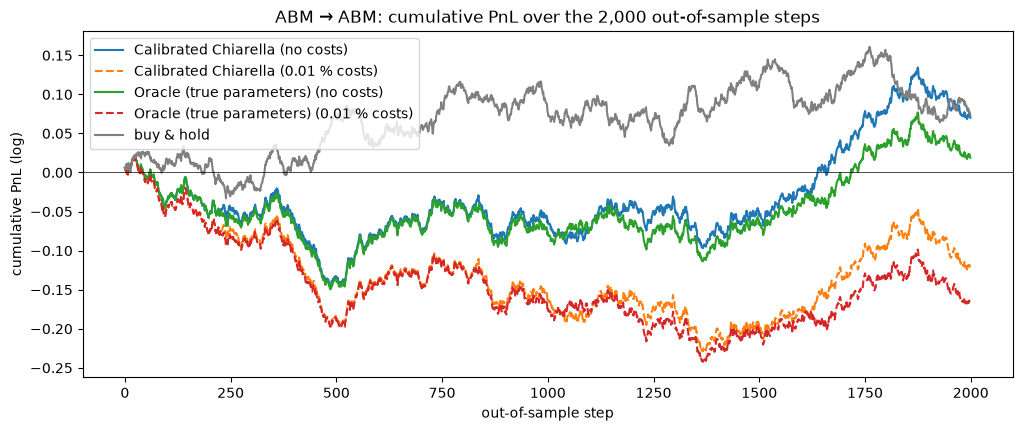

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for name, r_hat in forecasts.items():
    gains = np.sign(r_hat[test]) * r_sim[test]
    ax.plot(np.cumsum(gains), label=f"{name} (no costs)")
    changes = np.abs(np.diff(np.sign(r_hat[test]), prepend=0))
    ax.plot(np.cumsum(gains - 0.0001 * changes), ls="--", label=f"{name} (0.01 % costs)")
ax.plot(np.cumsum(r_sim[test]), color="gray", label="buy & hold")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("out-of-sample step")
ax.set_ylabel("cumulative PnL (log)")
ax.set_title("ABM → ABM: cumulative PnL over the 2,000 out-of-sample steps")
ax.legend()
plt.show()

**Monte Carlo over 50 series**: one 2,000-day series gives a very uncertain hit ratio (std ≈ 0.011 by pure chance).

In [6]:
rows = []
for seed in range(50):
    p_s, _, _ = chiarella_fast(**THETA_TRUE, T=T_CAL + T_PRED, rng=np.random.default_rng(1000 + seed))
    r_s = log_returns(p_s)
    F_s, C_s = regressors(p_s, THETA_TRUE["alpha"], THETA_TRUE["lam"], THETA_TRUE["gamma"])
    b, k = calibrate(F_s, C_s, r_s, 500, T_CAL)
    for name, (bb, kk) in {"calibrated": (b, k), "oracle": (THETA_TRUE["beta"], THETA_TRUE["kappa"])}.items():
        r_hat = predict(F_s, C_s, bb, kk)
        res = evaluate(np.sign(r_hat[test]), r_s[test])
        rows.append({"model": name, "hit ratio": res["hit ratio"], "net Sharpe": res["Sharpe (annualized)"],
                     "ρ": np.corrcoef(r_hat[test], r_s[test])[0, 1]})
mc = pd.DataFrame(rows)
summary = mc.groupby("model").agg(["mean", "std"]).round(4)
summary[("theoretical hit ratio", "mean")] = sheppard(mc.groupby("model")["ρ"].mean()).round(4)
print(f"Std of a hit ratio over {T_PRED} days by pure chance: {0.5 / np.sqrt(T_PRED):.4f}")
summary

Std of a hit ratio over 2000 days by pure chance: 0.0112


hit ratio         net Sharpe               ρ         \
                mean     std       mean     std    mean    std   
model                                                            
calibrated    0.5197  0.0109     0.2337  0.3756  0.0905  0.042   
oracle        0.5199  0.0123     0.2381  0.4014  0.0910  0.043   

           theoretical hit ratio  
                            mean  
model                             
calibrated                0.5288  
oracle                    0.5290

### What 6.1 shows

**On a single series, the true model can do worse than chance** (seed 0: 0.492 calibrated, 0.485 oracle, not significant), while the gross PnL is positive: the model is right on the **large** moves.

**Over 50 series, the ceiling appears**: hit ratio 0.520 ± 0.011 for both calibrated and oracle, ρ ≈ 0.09, Sheppard 0.529.
- **The maximum hit ratio is ≈ 0.52** even when the model is true. The 0.512 of the group slides was not a failure: it is the limit set by the model's signal-to-noise ratio.
- **Calibrated = oracle**: estimation error on β and κ costs nothing, since the forecast only depends on the well-estimated combinations (Part 4).
- **Sheppard slightly overestimates**: it assumes a Gaussian forecast, but r̂_det is heavy-tailed (the cubic term makes rare, very strong forecasts). Correlation is driven by those days; hit ratio counts all days equally.
- **Costs matter**: with 0.01 % per change, the mean net Sharpe is only ≈ 0.23 (the position flips often for a tiny daily edge).

### Position sizing by signal strength

The model is mostly right when its forecast is **strong**. Three sizings, on the 50 series:
- **sign**: ±1 every day;
- **proportional**: position ∝ r̂_det (scaled by the std of calibration-window forecasts, capped at ±2) — the theoretically optimal rule, position ∝ E[r]/Var(r);
- **threshold**: ±1 only when |r̂_det| exceeds the 80th percentile of past forecasts, 0 otherwise.

Scale and threshold come from the **calibration** window, never the test period.

In [7]:
def positions(r_hat, t_cal, t_test, threshold_pct=80, cap=2.0):
    """Three position sizes, tuned on the CALIBRATION window only (no look-ahead)."""
    past = r_hat[t_cal]
    past = past[~np.isnan(past)]
    scale = past.std()                                   # std of past forecasts
    threshold = np.percentile(np.abs(past), threshold_pct)
    future = r_hat[t_test]
    return {
        "sign": np.sign(future),
        "proportional": np.clip(future / scale, -cap, cap),
        "threshold (80th pct)": np.where(np.abs(future) > threshold, np.sign(future), 0.0),
    }


t_cal = np.arange(500, T_CAL)
rows = []
for seed in range(50):
    p_s, _, _ = chiarella_fast(**THETA_TRUE, T=T_CAL + T_PRED, rng=np.random.default_rng(1000 + seed))
    r_s = log_returns(p_s)
    F_s, C_s = regressors(p_s, THETA_TRUE["alpha"], THETA_TRUE["lam"], THETA_TRUE["gamma"])
    b, k = calibrate(F_s, C_s, r_s, 500, T_CAL)
    r_hat = predict(F_s, C_s, b, k)
    for name, pos in positions(r_hat, t_cal, test).items():
        res = evaluate(pos, r_s[test])
        rows.append({"sizing": name, "hit ratio (traded days)": res["hit ratio"],
                     "traded days (%)": 100 * np.mean(pos != 0),
                     "net PnL": res["net PnL"], "net Sharpe": res["Sharpe (annualized)"]})
sizings = pd.DataFrame(rows)
sizings.groupby("sizing").mean().reindex(["sign", "proportional", "threshold (80th pct)"]).round(4)

,hit ratio (traded days),traded days (%),net PnL,net Sharpe
sizing,,,,
sign,0.5197,100.000,0.0882,0.2337
proportional,0.5197,100.000,0.2121,0.7250
threshold (80th pct),0.5592,20.251,0.1220,0.6814


- **Betting on signal strength triples the Sharpe** (0.23 → 0.73 for proportional): same signs, hence same hit ratio, but large bets exactly when the model is right.
- **The threshold confirms it**: trading only the 20 % strongest days lifts the hit ratio from 0.52 to 0.56, and costs shrink since the position rarely changes.

**Mean PnL over the Monte Carlo.** PnL is a sum of log returns (0.10 ≈ +10.5 %). Strategies have different average sizes, so the **Sharpe** (gain per unit of risk) is the fairer comparison.

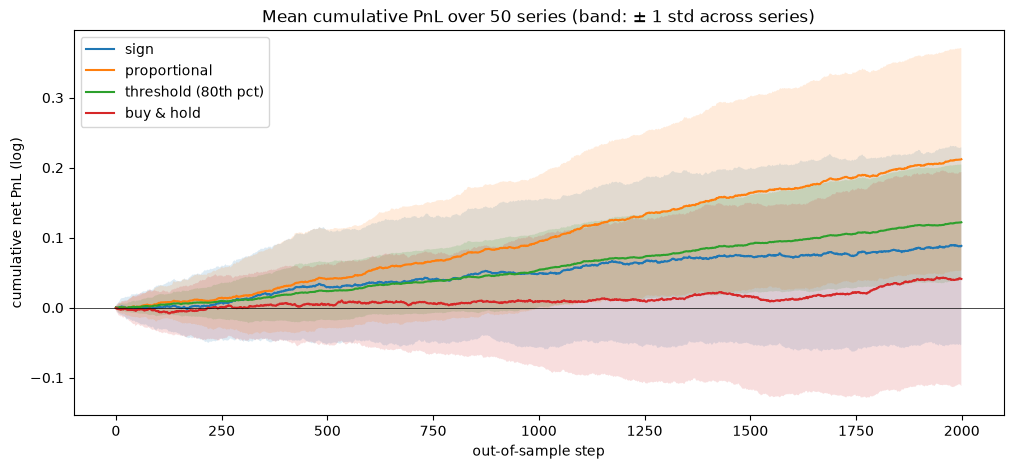

,mean net PnL,std across series,winning series (%)
sign,0.0882,0.1407,74.0
proportional,0.2121,0.1584,92.0
threshold (80th pct),0.1220,0.0824,98.0
buy & hold,0.0411,0.1528,62.0


In [8]:
COST = 0.0001
curves = {name: [] for name in ["sign", "proportional", "threshold (80th pct)", "buy & hold"]}
for seed in range(50):
    p_s, _, _ = chiarella_fast(**THETA_TRUE, T=T_CAL + T_PRED, rng=np.random.default_rng(1000 + seed))
    r_s = log_returns(p_s)
    F_s, C_s = regressors(p_s, THETA_TRUE["alpha"], THETA_TRUE["lam"], THETA_TRUE["gamma"])
    b, k = calibrate(F_s, C_s, r_s, 500, T_CAL)
    all_pos = {**positions(predict(F_s, C_s, b, k), t_cal, test), "buy & hold": np.ones(len(test))}
    for name, pos in all_pos.items():
        gains = pos * r_s[test] - COST * np.abs(np.diff(pos, prepend=0.0))
        curves[name].append(np.cumsum(gains))

fig, ax = plt.subplots(figsize=(12, 5))
rows = {}
for name, lst in curves.items():
    lst = np.array(lst)                       # (50 series, 2000 steps)
    mean, std = lst.mean(axis=0), lst.std(axis=0)
    ax.plot(mean, label=name)
    ax.fill_between(np.arange(len(mean)), mean - std, mean + std, alpha=0.15)
    final = lst[:, -1]
    rows[name] = {"mean net PnL": final.mean(), "std across series": final.std(),
                  "winning series (%)": 100 * np.mean(final > 0)}
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("out-of-sample step")
ax.set_ylabel("cumulative net PnL (log)")
ax.set_title("Mean cumulative PnL over 50 series (band: ± 1 std across series)")
ax.legend()
plt.show()
pd.DataFrame(rows).T.round(4)

## 6.2 Signal-to-noise ratio

Strengthen the agents to see when prediction becomes possible: first the chartists (β, hence c = βγα), then the fundamentalists (κ, hence g = 3κσ²/2λ), staying away from the explosion frontier. 20 series per value: calibration, out-of-sample prediction.

In [9]:
sweeps = {
    "chartists: β varies (κ = 50)": [{"beta": b} for b in [0.0, 0.05, 0.1, 0.2, 0.3, 0.4]],
    "fundamentalists: κ varies (β = 0.05)": [{"kappa": k} for k in [0, 25, 50, 100, 150]],
}
N_SERIES = 20
rows = []
for sweep_name, variations in sweeps.items():
    for variation in variations:
        theta_s = {**THETA_TRUE, **variation}
        hits, rhos = [], []
        for seed in range(N_SERIES):
            p_s, _, _ = chiarella_fast(**theta_s, T=T_CAL + T_PRED, rng=np.random.default_rng(2000 + seed))
            if np.isnan(p_s).any():   # exploding series: skipped
                continue
            r_s = log_returns(p_s)
            F_s, C_s = regressors(p_s, theta_s["alpha"], theta_s["lam"], theta_s["gamma"])
            b, k = calibrate(F_s, C_s, r_s, 500, T_CAL)
            r_hat = predict(F_s, C_s, b, k)
            hits.append(evaluate(np.sign(r_hat[test]), r_s[test])["hit ratio"])
            rhos.append(np.corrcoef(r_hat[test], r_s[test])[0, 1])
        c = theta_s["beta"] * theta_s["gamma"] * theta_s["alpha"]
        g = 3 * theta_s["kappa"] * theta_s["sigma"] ** 2 / (2 * theta_s["lam"])
        rows.append({"sweep": sweep_name, **variation, "c = βγα": c, "g = 3κσ²/2λ": g,
                     "series": len(hits), "mean ρ": np.mean(rhos), "mean hit ratio": np.mean(hits),
                     "theoretical hit ratio": sheppard(np.mean(rhos))})
snr = pd.DataFrame(rows)
snr.round(4)

,sweep,beta,c = βγα,g = 3κσ²/2λ,series,mean ρ,mean hit ratio,theoretical hit ratio,kappa
0,chartists: β varies (κ = 50),0.00,0.00,0.0675,20,0.0988,0.5204,0.5315,NaN
1,chartists: β varies (κ = 50),0.05,0.05,0.0675,20,0.0798,0.5143,0.5254,NaN
2,chartists: β varies (κ = 50),0.10,0.10,0.0675,20,0.0902,0.5224,0.5288,NaN
3,chartists: β varies (κ = 50),0.20,0.20,0.0675,20,0.1625,0.5496,0.5520,NaN
4,chartists: β varies (κ = 50),0.30,0.30,0.0675,20,0.2553,0.5800,0.5822,NaN
5,chartists: β varies (κ = 50),0.40,0.40,0.0675,20,0.3524,0.6117,0.6146,NaN
6,fundamentalists: κ varies (β = 0.05),NaN,0.05,0.0000,20,0.0448,0.5127,0.5143,0.0
7,fundamentalists: κ varies (β = 0.05),NaN,0.05,0.0338,20,0.0442,0.5114,0.5141,25.0
8,fundamentalists: κ varies (β = 0.05),NaN,0.05,0.0675,20,0.0798,0.5143,0.5254,50.0
9,fundamentalists: κ varies (β = 0.05),NaN,0.05,0.1350,20,0.1923,0.5319,0.5616,100.0


Observed hit ratio against Sheppard's formula. Targeting a hit ratio h requires ρ = sin((h − ½)·π).

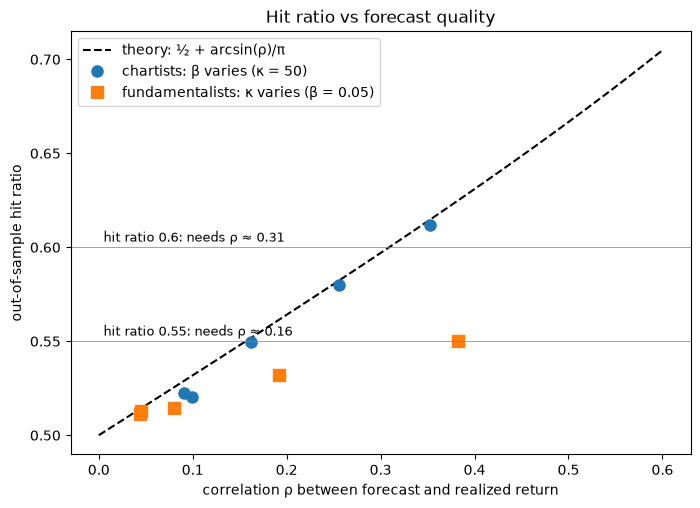

In [10]:
grid = np.linspace(0, 0.6, 100)
plt.figure(figsize=(8, 5.5))
plt.plot(grid, sheppard(grid), "k--", label="theory: ½ + arcsin(ρ)/π")
for (name, group), marker in zip(snr.groupby("sweep"), ["o", "s"]):
    plt.plot(group["mean ρ"], group["mean hit ratio"], marker, ms=8, label=name)
for target in (0.55, 0.60):
    rho_needed = np.sin((target - 0.5) * np.pi)
    plt.axhline(target, color="gray", lw=0.5)
    plt.text(0.005, target + 0.003, f"hit ratio {target}: needs ρ ≈ {rho_needed:.2f}", fontsize=9)
plt.xlabel("correlation ρ between forecast and realized return")
plt.ylabel("out-of-sample hit ratio")
plt.title("Hit ratio vs forecast quality")
plt.legend()
plt.savefig("../figures/prediction_sheppard.png", dpi=150, bbox_inches="tight")  # README figure
plt.show()

### What 6.2 shows

- **Chartists**: the hit ratio follows Sheppard almost exactly: 0.55 at ρ ≈ 0.16 (β = 0.2), 0.61 at ρ ≈ 0.35 (β = 0.4).
- **Fundamentalists**: the hit ratio rises much less than theory (0.55 vs 0.62 at κ = 150): their cubic forecast is heavy-tailed, near zero most of the time and very strong occasionally.
- **The two effects offset**: ρ ≈ 0.10 at β = 0 but only 0.08 at β = 0.05. A little momentum partly cancels the fundamentalists' resistance (c − g → 0) and the model becomes *less* predictable.

**What good prediction would require**: ρ ≈ 0.16 for 0.55, ρ ≈ 0.31 for 0.60, i.e. a lag-1 return autocorrelation of 0.2–0.4 on the chartist side. Part 1 showed this is unrealistic (S&P 500: −0.11; such autocorrelation would be an obvious arbitrage). **In realistic regimes, a model of this type can hardly exceed 0.53.**

## 6.3 ABM → S&P 500: rolling window

The real test. `backtest` calibrates (β, κ) by least squares on 500 days, predicts the next 20, shifts by 20 days, and so on. The state is rebuilt once from prices (it only uses the past: no look-ahead); the test starts at day 1,000 so the initial state is forgotten. γ = 10 (unit convention). Two sets of memories (α, λ): Parts 2–4, and the NFT trader horizons of Part 5. Costs: 0.01 % per position change. The three sizings of 6.1 are tuned on each calibration window only.

In [11]:
sp500 = pd.read_csv("../data/sp500_daily.csv", index_col="date", parse_dates=True)
dates = sp500.index
p_sp = np.log(sp500["adj_close"].to_numpy())
r_sp = log_returns(p_sp)
print(f"S&P 500: {len(p_sp)} days, from {dates[0].date()} to {dates[-1].date()}")
print(f"Lag-1 return autocorrelation: {pd.Series(r_sp).autocorr(1):+.3f}")

S&P 500: 4218 days, from 2010-01-04 to 2026-10-09
Lag-1 return autocorrelation: -0.111


In [12]:
from abm import backtest

START = 1000
param_sets = {
    "α = 0.1, λ = 0.01 (Parts 2–4)": (0.1, 0.01),
    "α = 0.087, λ = 0.2 (NFT horizons, Part 5)": (0.087, 0.2),
}
results, parameters = {}, {}
for set_name, (alpha, lam) in param_sets.items():
    sizes_sp, params = backtest(p_sp, alpha, lam, 10.0, start=START)
    params.index = dates[params.index]   # date of the first day predicted by each window
    parameters[set_name] = params
    for size_name, position in sizes_sp.items():
        results[f"Chiarella {set_name} · {size_name}"] = position
for name, position in benchmark_strategies(r_sp).items():
    results[name] = position

period = slice(START, len(p_sp))
table_sp = pd.DataFrame({name: evaluate(pos[period], r_sp[period]) for name, pos in results.items()}).T
print(f"Test period: {dates[START].date()} to {dates[-1].date()} ({len(p_sp) - START} days), costs 0.01 %")
table_sp[["hit ratio", "p-value (vs 0.5)", "precision up", "precision down", "net PnL", "Sharpe (annualized)"]].round(3)

Test period: 2013-12-23 to 2026-10-09 (3218 days), costs 0.01 %


,hit ratio,p-value (vs 0.5),precision up,precision down,net PnL,Sharpe (annualized)
"Chiarella α = 0.1, λ = 0.01 (Parts 2–4) · sign",0.513,0.139,0.558,0.472,-0.962,-0.436
"Chiarella α = 0.1, λ = 0.01 (Parts 2–4) · proportional",0.513,0.139,0.558,0.472,-1.048,-0.403
"Chiarella α = 0.1, λ = 0.01 (Parts 2–4) · threshold (80th pct)",0.515,0.478,0.554,0.477,-0.348,-0.240
"Chiarella α = 0.087, λ = 0.2 (NFT horizons, Part 5) · sign",0.505,0.573,0.547,0.463,-0.344,-0.156
"Chiarella α = 0.087, λ = 0.2 (NFT horizons, Part 5) · proportional",0.505,0.573,0.547,0.463,0.204,0.082
"Chiarella α = 0.087, λ = 0.2 (NFT horizons, Part 5) · threshold (80th pct)",0.495,0.844,0.516,0.475,-0.093,-0.061
buy & hold,0.542,0.000,0.542,NaN,1.458,0.662
naive momentum: sign(r_t),0.482,0.039,0.522,0.434,-1.356,-0.616
naive mean reversion: -sign(r_t),0.518,0.039,0.566,0.478,0.689,0.313


**Cumulative net PnL** over the test period, for the naive strategies and the main Chiarella variants.

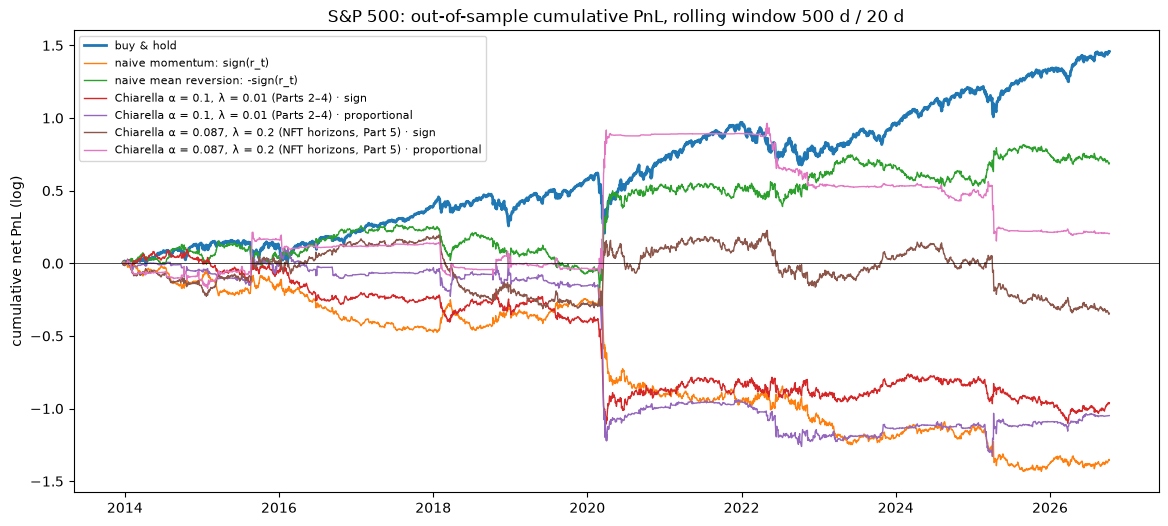

In [13]:
to_plot = ["buy & hold", "naive momentum: sign(r_t)", "naive mean reversion: -sign(r_t)"] + [
    f"Chiarella {set_name} · {size}" for set_name in param_sets for size in ["sign", "proportional"]]

fig, ax = plt.subplots(figsize=(14, 6))
for name in to_plot:
    pos = results[name][period]
    gains = pos * r_sp[period] - 0.0001 * np.abs(np.diff(pos, prepend=0.0))
    ax.plot(dates[period], np.cumsum(gains), lw=2 if name == "buy & hold" else 1, label=name)
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("cumulative net PnL (log)")
ax.set_title("S&P 500: out-of-sample cumulative PnL, rolling window 500 d / 20 d")
ax.legend(fontsize=8)
plt.show()

**Parameter stability**: if the model described a stable mechanism, β̂ and κ̂ would keep roughly the same sign and size from one window to the next.

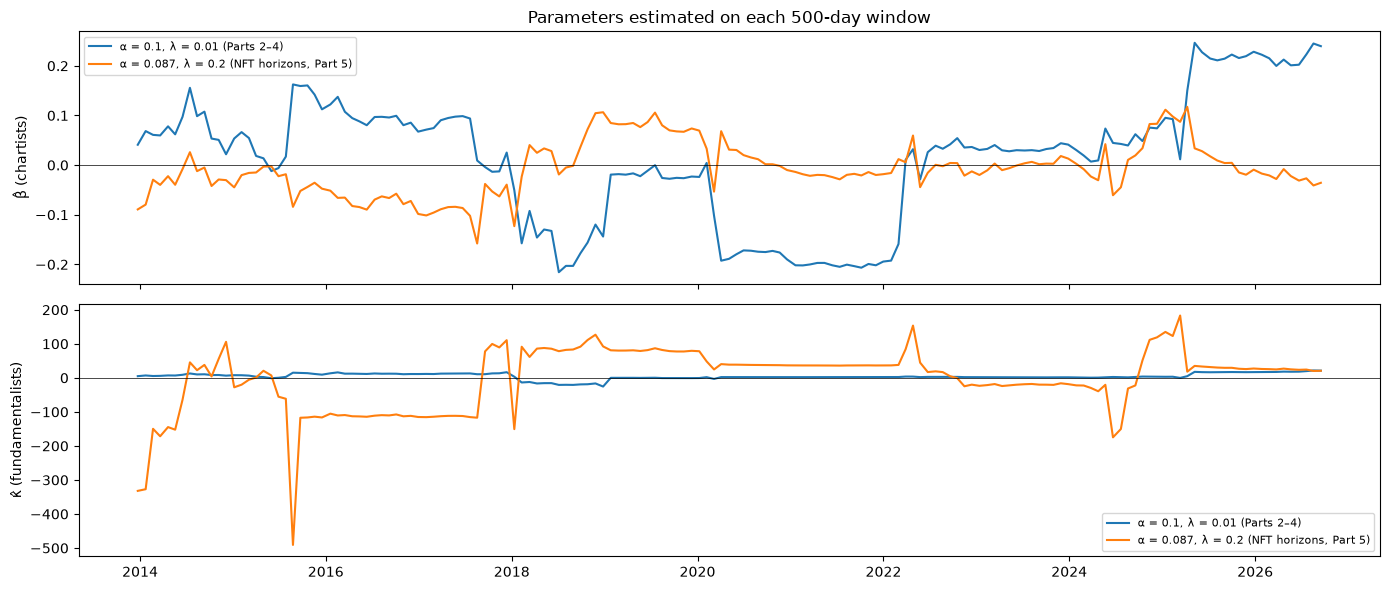

Share of up days for the S&P 500: 0.542


In [14]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for set_name, df in parameters.items():
    axes[0].plot(df.index, df["beta"], label=set_name)
    axes[1].plot(df.index, df["kappa"], label=set_name)
for ax, name in zip(axes, ["β̂ (chartists)", "κ̂ (fundamentalists)"]):
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylabel(name)
    ax.legend(fontsize=8)
axes[0].set_title("Parameters estimated on each 500-day window")
plt.tight_layout()
plt.show()
print(f"Share of up days for the S&P 500: {np.mean(r_sp[period] > 0):.3f}")

### What 6.3 shows (test: Dec 2013 – Oct 2026, 3,218 days)

| Strategy | Hit ratio | p-value | Net PnL | Sharpe |
|---|---|---|---|---|
| **Buy & hold** | 0.542 | < 0.001 | **+1.46** | **0.66** |
| Naive mean reversion | 0.518 | 0.04 | +0.69 | 0.31 |
| Chiarella (α = 0.1, λ = 0.01), sign | 0.513 | 0.14 | −0.96 | −0.44 |
| Chiarella (NFT horizons), proportional | 0.505 | 0.57 | +0.20 | 0.08 |
| Naive momentum | 0.482 | 0.04 | −1.36 | −0.62 |

1. **The model does not significantly beat chance** (0.505–0.515, p from 0.14 to 0.84), consistent with the ≈ 0.53 ceiling of 6.2.
2. **A hit ratio above 0.5 can lose money** (0.513, net PnL −0.96): the model is wrong on the **large** moves (fat tails, 6.4).
3. **It does not beat a trivial rule**: naive mean reversion (−sign of yesterday's return) does better on every criterion, directly exploiting the S&P 500's −0.11 autocorrelation.
4. **Nothing beats buy & hold**: the index rises 54 % of days. The higher "up" precision of all strategies is the market's drift, not skill.
5. **NFT horizons do slightly better**: with λ = 0.2, the fundamentalist term captures short-term mean reversion, close to the naive rule that works.
6. **Unstable parameters**: β̂ changes sign several times, κ̂ is sometimes strongly **negative** (economically meaningless), and estimates jump when a crisis enters or leaves the window (2018, 2020, 2022). Fat tails dominate the calibration — the motivation for 6.4.

> The 0.499 of the group slides and my 0.505–0.515 tell the same story: on the daily S&P 500, the Chiarella model holds no exploitable predictive information.

## 6.4 Fat tails

### (a) Calibrating without being dominated by extremes

Least squares **square** the residuals: a 10-sigma crash weighs 100 times a 1-sigma day and can alone set β̂ and κ̂. Two fixes, applied **within the calibration window only** (no look-ahead):
- **winsorization**: returns beyond ±3 std are clipped to ±3 std;
- **Huber loss**: quadratic for small residuals, **linear** beyond 1.345 std (the classic setting), reducing the influence of extremes without removing them.

In [15]:
from abm import calibrate_winsor, calibrate_huber

calibrations = {"least squares": calibrate, "winsorization ±3σ": calibrate_winsor, "Huber": calibrate_huber}
robustness = {}
for set_name, (alpha, lam) in param_sets.items():
    for cal_name, function in calibrations.items():
        sizes_r, _ = backtest(p_sp, alpha, lam, 10.0, function, start=START)
        for size_name in ["sign", "proportional"]:
            res = evaluate(sizes_r[size_name][period], r_sp[period])
            robustness[(set_name, cal_name, size_name)] = {k: res[k] for k in ["hit ratio", "net PnL", "Sharpe (annualized)"]}
            results[f"Chiarella {set_name} · {cal_name} · {size_name}"] = sizes_r[size_name]
pd.DataFrame(robustness).T.round(3)

hit ratio  \
α = 0.1, λ = 0.01 (Parts 2–4)             least squares     sign              0.513   
                                                            proportional      0.513   
                                          winsorization ±3σ sign              0.508   
                                                            proportional      0.508   
                                          Huber             sign              0.511   
                                                            proportional      0.511   
α = 0.087, λ = 0.2 (NFT horizons, Part 5) least squares     sign              0.505   
                                                            proportional      0.505   
                                          winsorization ±3σ sign              0.506   
                                                            proportional      0.506   
                                          Huber             sign              0.512   
                                                            proportional      0.512   

                                                                          net PnL  \
α = 0.1, λ = 0.01 (Parts 2–4)             least squares     sign           -0.962   
                                                            proportional   -1.048   
                                          winsorization ±3σ sign           -0.802   
                                                            proportional   -0.560   
                                          Huber             sign           -0.709   
                                                            proportional   -0.850   
α = 0.087, λ = 0.2 (NFT horizons, Part 5) least squares     sign           -0.344   
                                                            proportional    0.204   
                                          winsorization ±3σ sign           -0.018   
                                                            proportional    0.259   
                                          Huber             sign           -0.167   
                                                            proportional    0.066   

                                                                          Sharpe (annualized)  
α = 0.1, λ = 0.01 (Parts 2–4)             least squares     sign                       -0.436  
                                                            proportional               -0.403  
                                          winsorization ±3σ sign                       -0.364  
                                                            proportional               -0.208  
                                          Huber             sign                       -0.322  
                                                            proportional               -0.311  
α = 0.087, λ = 0.2 (NFT horizons, Part 5) least squares     sign                       -0.156  
                                                            proportional                0.082  
                                          winsorization ±3σ sign                       -0.008  
                                                            proportional                0.104  
                                          Huber             sign                       -0.076  
                                                            proportional                0.026

### (b) Where is the PnL made: normal or extreme days?

A day is **extreme** if |r_t| exceeds 3 times the volatility of the **previous** 20 days. This decomposition is only to **understand** the PnL: extreme days are never removed from the evaluation, since they cannot be known in advance.

In [16]:
vol_20 = pd.Series(r_sp).rolling(20).std().shift(1).to_numpy()   # known the day before
extreme = np.abs(r_sp) > 3 * vol_20
print(f"Extreme days in the test period: {extreme[period].sum()} of {len(r_sp[period])} "
      f"({100 * extreme[period].mean():.1f} %)")

to_decompose = [
    "buy & hold",
    "naive mean reversion: -sign(r_t)",
    "Chiarella α = 0.1, λ = 0.01 (Parts 2–4) · least squares · sign",
    "Chiarella α = 0.1, λ = 0.01 (Parts 2–4) · Huber · sign",
    "Chiarella α = 0.087, λ = 0.2 (NFT horizons, Part 5) · Huber · proportional",
]
rows = {}
for name in to_decompose:
    pos, r_p, ext = results[name][period], r_sp[period], extreme[period]
    gains = pos * r_p - 0.0001 * np.abs(np.diff(pos, prepend=0.0))
    rows[name] = {"PnL normal days": np.nansum(gains[~ext]), "PnL extreme days": np.nansum(gains[ext]),
                  "total PnL": np.nansum(gains)}
pd.DataFrame(rows).T.round(3)

Extreme days in the test period: 61 of 3218 (1.9 %)


,PnL normal days,PnL extreme days,total PnL
buy & hold,2.540,-1.083,1.458
naive mean reversion: -sign(r_t),1.054,-0.364,0.689
"Chiarella α = 0.1, λ = 0.01 (Parts 2–4) · least squares · sign",-0.312,-0.649,-0.962
"Chiarella α = 0.1, λ = 0.01 (Parts 2–4) · Huber · sign",-0.482,-0.228,-0.709
"Chiarella α = 0.087, λ = 0.2 (NFT horizons, Part 5) · Huber · proportional",0.624,-0.558,0.066


### (c) Managing risk with past volatility

The **direction** of the next shock cannot be predicted, but **turbulent** periods can (volatility clustering). Two rules using only the past:
- **filter**: flat when the 20-day volatility exceeds its 80th percentile over the previous 500 days;
- **volatility targeting** (Moreira and Muir, 2017): position × σ_target / σ̂, with σ_target the median volatility of the previous 500 days, capped at 2.

The last row (buy & hold + targeting) isolates the effect of risk management **without** the model.

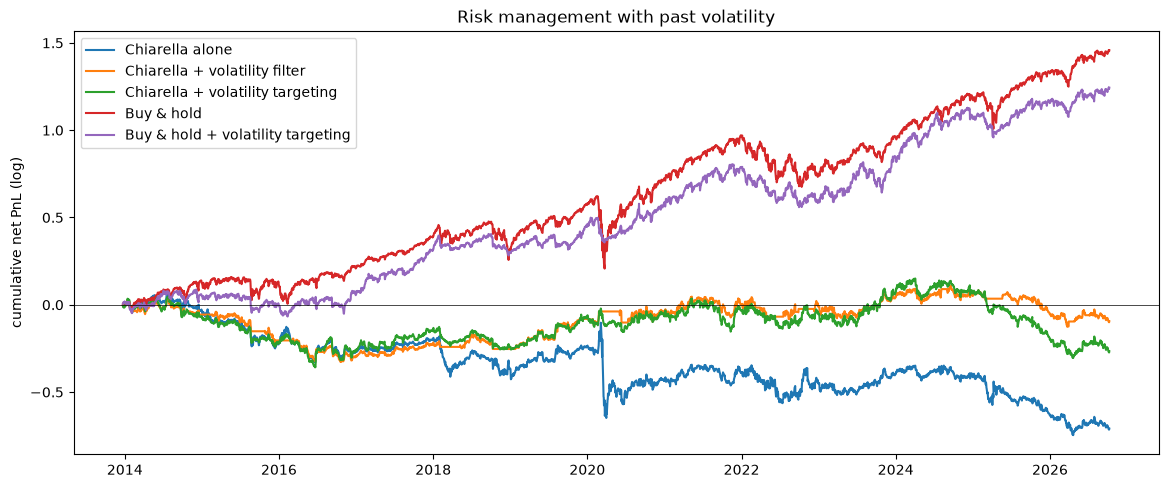

,hit ratio,net PnL,Sharpe,max drawdown
Chiarella alone,0.511,-0.709,-0.322,0.811
Chiarella + volatility filter,0.515,-0.094,-0.065,0.354
Chiarella + volatility targeting,0.511,-0.266,-0.149,0.456
Buy & hold,0.542,1.458,0.662,0.414
Buy & hold + volatility targeting,0.542,1.244,0.698,0.245


In [17]:
from abm import max_drawdown

sigma_hat = pd.Series(r_sp).rolling(20).std().shift(1).to_numpy()            # known at the end of day t
vol_threshold = pd.Series(sigma_hat).rolling(500).quantile(0.8).to_numpy()   # "turbulent" = 80th percentile
sigma_target = pd.Series(sigma_hat).rolling(500).median().to_numpy()         # "normal" volatility


def vol_filter(position):
    return np.where(sigma_hat > vol_threshold, 0.0, position)


def vol_targeting(position, cap=2.0):
    return np.clip(position * sigma_target / sigma_hat, -cap, cap)


chiarella_pos = results["Chiarella α = 0.1, λ = 0.01 (Parts 2–4) · Huber · sign"]
vol_strategies = {
    "Chiarella alone": chiarella_pos,
    "Chiarella + volatility filter": vol_filter(chiarella_pos),
    "Chiarella + volatility targeting": vol_targeting(chiarella_pos),
    "Buy & hold": np.ones(len(r_sp)),
    "Buy & hold + volatility targeting": vol_targeting(np.ones(len(r_sp))),
}

rows = {}
fig, ax = plt.subplots(figsize=(14, 5.5))
for name, pos in vol_strategies.items():
    res = evaluate(pos[period], r_sp[period])
    gains = pos[period] * r_sp[period] - 0.0001 * np.abs(np.diff(pos[period], prepend=0.0))
    rows[name] = {"hit ratio": res["hit ratio"], "net PnL": res["net PnL"], "Sharpe": res["Sharpe (annualized)"],
                  "max drawdown": max_drawdown(gains)}
    ax.plot(dates[period], np.cumsum(np.nan_to_num(gains)), label=name)
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("cumulative net PnL (log)")
ax.set_title("Risk management with past volatility")
ax.legend()
plt.savefig("../figures/prediction_vol_targeting.png", dpi=150, bbox_inches="tight")  # README figure
plt.show()
pd.DataFrame(rows).T.round(3)

### What 6.4 shows

**(a) Robust calibration reduces losses without creating signal.** Hit ratio stays at 0.505–0.513 whatever the method; PnL improves a little (α = 0.1, λ = 0.01, sign: −0.96 least squares, −0.71 Huber, −0.80 winsorization). The best variant reaches a Sharpe of 0.10, far from buy & hold's 0.66.

**(b) 2 % of days weigh heavily.** 61 extreme days out of 3,218:

| | PnL normal days | PnL extreme days | Total |
|---|---|---|---|
| Buy & hold | +2.54 | **−1.08** | +1.46 |
| Naive mean reversion | +1.05 | −0.36 | +0.69 |
| Chiarella (NFT horizons, Huber, proportional) | **+0.62** | **−0.56** | +0.07 |
| Chiarella (α = 0.1, λ = 0.01, Huber, sign) | −0.48 | −0.23 | −0.71 |

The best Chiarella variant earns +0.62 on normal days and gives almost all of it back (−0.56) on 61 days. Even buy & hold loses 40 % of its normal-day gains on those 2 % of days.

**(c) Risk management works; the model has nothing to do with it.**

| | Net PnL | Sharpe | Max drawdown |
|---|---|---|---|
| Chiarella alone | −0.71 | −0.32 | 0.81 |
| Chiarella + volatility filter | −0.09 | −0.07 | 0.35 |
| Chiarella + volatility targeting | −0.27 | −0.15 | 0.46 |
| Buy & hold | +1.46 | 0.66 | 0.41 |
| **Buy & hold + volatility targeting** | +1.24 | **0.70** | **0.25** |

The filter divides Chiarella's losses by 8 and its drawdown by 2, but the best strategy is **buy & hold with volatility targeting** (best Sharpe, drawdown almost halved): **risk management creates the performance, not the model** — Moreira and Muir's (2017) result.

## 6.5 Currencies

No long-term drift (a fair comparison with buy & hold), a real fundamental value the rate reverts to in the long run, fewer crashes than equities: better ground for Chiarella than the S&P 500. Nine pairs, daily since 2000–2006.

### Cleaning

Yahoo FX data contain **one-day errors**: an aberrant rate that reverts the next day (EURUSD +16 % then −14 % on 8–9 Dec 2008). They are replaced by the previous rate, checking that real events (Swiss franc 2015, Brexit 2016) are kept.

In [18]:
fx_raw = pd.read_csv("../data/fx_daily.csv", index_col="date", parse_dates=True)
PAIRS = list(fx_raw.columns)

from abm import clean_fx   # one-day error cleaning rule

fx = {}
rows = {}
for pair in PAIRS:
    raw_p = fx_raw[pair].dropna()
    clean_p, error = clean_fx(raw_p)
    fx[pair] = clean_p
    r_before, r_after = np.log(raw_p).diff(), np.log(clean_p).diff()
    biggest = r_after.abs().idxmax()
    rows[pair] = {
        "days": len(raw_p), "start": raw_p.index[0].date(), "days corrected": int(error.sum()),
        "kurtosis before": r_before.kurt(), "kurtosis after": r_after.kurt(),
        "autocorr. before": r_before.autocorr(1), "autocorr. after": r_after.autocorr(1),
        "largest move kept": f"{biggest.date()} ({r_after[biggest]:+.1%})",
    }
pd.DataFrame(rows).T.round(3)

,days,start,days corrected,kurtosis before,kurtosis after,autocorr. before,autocorr. after,largest move kept
AUDUSD,5316,2006-05-16,1,13.156208,13.189991,-0.053902,-0.052057,2008-10-13 (+9.0%)
EURGBP,6980,2000-01-03,2,58.74088,5.211359,-0.073886,-0.009302,2016-06-27 (+5.4%)
EURJPY,6165,2003-01-23,0,8.503196,8.503196,-0.050012,-0.050012,2008-10-28 (+7.9%)
EURUSD,5940,2003-12-01,5,100.829599,2.754619,-0.175184,-0.02132,2008-08-08 (-3.6%)
GBPUSD,5952,2003-12-01,0,8.912238,8.912238,0.018173,0.018173,2016-06-27 (-7.9%)
NZDUSD,5941,2003-12-01,0,3.838025,3.838025,-0.008162,-0.008162,2008-10-24 (-6.8%)
USDCAD,6008,2003-09-17,1,3.517259,3.278755,-0.0203,-0.016828,2008-10-29 (-3.7%)
USDCHF,6006,2003-09-17,1,100.138092,103.320911,-0.038121,-0.009214,2015-01-16 (-17.6%)
USDJPY,6960,2000-01-03,3,100.768697,4.340032,-0.155141,-0.047785,2008-10-28 (+5.2%)


### Daily backtest

Same setup as 6.3. The **main strategy** is fixed **before** looking at results (Chiarella, α = 0.1, λ = 0.01, sign sizing); the Bonferroni correction for 9 pairs applies to it. PnL ignores carry (interest-rate differential).

In [19]:
MAIN_STRATEGY = "Chiarella α = 0.1, λ = 0.01 · sign"   # chosen BEFORE looking at the results
BONFERRONI = 0.05 / len(PAIRS)

rows, overview = [], {}
for pair in PAIRS:
    p_fx = np.log(fx[pair].to_numpy())
    r_fx = log_returns(p_fx)
    test_fx = slice(START, len(p_fx))
    strategies = {}
    for set_name, (alpha, lam) in {"α = 0.1, λ = 0.01": (0.1, 0.01), "NFT horizons": (0.087, 0.2)}.items():
        sizes_fx, _ = backtest(p_fx, alpha, lam, 10.0, calibrate, start=START)
        for size_name in ["sign", "proportional"]:
            strategies[f"Chiarella {set_name} · {size_name}"] = sizes_fx[size_name]
    strategies.update(benchmark_strategies(r_fx))
    for name, pos in strategies.items():
        res = evaluate(pos[test_fx], r_fx[test_fx])
        rows.append({"pair": pair, "strategy": name, "hit ratio": res["hit ratio"],
                     "p-value": res["p-value (vs 0.5)"], "Sharpe": res["Sharpe (annualized)"]})
    main = evaluate(strategies[MAIN_STRATEGY][test_fx], r_fx[test_fx])
    naives = {n: evaluate(strategies[n][test_fx], r_fx[test_fx])["Sharpe (annualized)"]
              for n in ["naive momentum: sign(r_t)", "naive mean reversion: -sign(r_t)"]}
    overview[pair] = {
        "lag-1 autocorr. (test)": pd.Series(r_fx[test_fx]).autocorr(1),
        "Chiarella: hit ratio": main["hit ratio"],
        "Chiarella: p-value": main["p-value (vs 0.5)"],
        "Chiarella: Sharpe": main["Sharpe (annualized)"],
        "best naive rule: Sharpe": max(naives.values()),
        f"significant (p < {BONFERRONI:.4f})": main["p-value (vs 0.5)"] < BONFERRONI,
    }
detail_fx = pd.DataFrame(rows)
overview_fx = pd.DataFrame(overview).T
print(f"Main strategy: {MAIN_STRATEGY} | Bonferroni threshold: {BONFERRONI:.4f}")
overview_fx.round(3)

Main strategy: Chiarella α = 0.1, λ = 0.01 · sign | Bonferroni threshold: 0.0056


,lag-1 autocorr. (test),Chiarella: hit ratio,Chiarella: p-value,Chiarella: Sharpe,best naive rule: Sharpe,significant (p < 0.0056)
AUDUSD,-0.025508,0.510693,0.165308,0.020151,0.370121,False
EURGBP,0.001253,0.500168,0.989648,-0.245355,-0.164538,False
EURJPY,-0.05799,0.501163,0.878296,-0.218529,0.309248,False
EURUSD,-0.015945,0.492367,0.291085,-0.278026,-0.006889,False
GBPUSD,0.023347,0.493614,0.377375,-0.023526,-0.066537,False
NZDUSD,-0.014703,0.484651,0.032448,-0.430007,0.032769,False
USDCAD,-0.006731,0.503002,0.6816,-0.432525,-0.244201,False
USDCHF,0.002103,0.494188,0.419722,-0.332156,-0.134261,False
USDJPY,-0.048253,0.507171,0.275231,-0.116976,0.149884,False


**Detail**: Sharpe of every strategy on every pair. Beware of picking the best cell: among 63 combinations, the best one is largely luck.

In [20]:
detail_fx.pivot(index="strategy", columns="pair", values="Sharpe").round(2)

pair,AUDUSD,EURGBP,EURJPY,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY
strategy,,,,,,,,,
Chiarella NFT horizons · proportional,0.58,-0.23,0.20,-0.36,-0.07,0.02,-0.15,-0.74,-0.10
Chiarella NFT horizons · sign,-0.01,-0.48,-0.03,-0.37,0.01,-0.20,-0.21,-0.83,-0.37
"Chiarella α = 0.1, λ = 0.01 · proportional",0.16,-0.14,-0.14,-0.32,0.19,-0.12,-0.46,-0.43,0.22
"Chiarella α = 0.1, λ = 0.01 · sign",0.02,-0.25,-0.22,-0.28,-0.02,-0.43,-0.43,-0.33,-0.12
buy & hold,-0.15,0.11,0.06,-0.13,-0.23,-0.12,0.18,-0.19,0.15
naive mean reversion: -sign(r_t),0.37,-0.16,0.31,-0.01,-0.46,0.03,-0.24,-0.13,0.15
naive momentum: sign(r_t),-0.88,-0.50,-0.76,-0.56,-0.07,-0.45,-0.36,-0.38,-0.69


**What to look at**: x-axis, each pair's autocorrelation. The naive rule's performance (squares) follows it; Chiarella's (circles) follows nothing in particular.

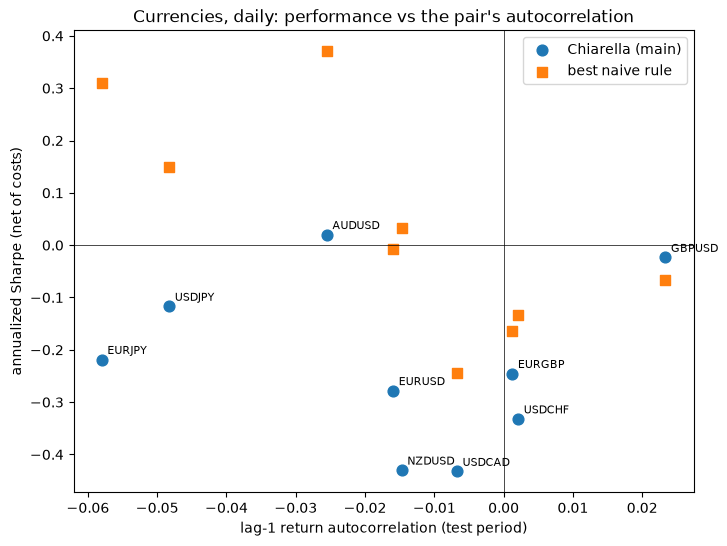

In [21]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(overview_fx["lag-1 autocorr. (test)"], overview_fx["Chiarella: Sharpe"], s=60, label="Chiarella (main)")
ax.scatter(overview_fx["lag-1 autocorr. (test)"], overview_fx["best naive rule: Sharpe"], s=60, marker="s",
           label="best naive rule")
for pair, row in overview_fx.iterrows():
    ax.annotate(pair, (row["lag-1 autocorr. (test)"], row["Chiarella: Sharpe"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.axhline(0, color="k", lw=0.5)
ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel("lag-1 return autocorrelation (test period)")
ax.set_ylabel("annualized Sharpe (net of costs)")
ax.set_title("Currencies, daily: performance vs the pair's autocorrelation")
ax.legend()
plt.show()

### Monthly backtest

Majewski et al.'s scale. One step = one month: α = 0.25 (trend over ≈ 4 months), λ = 0.05 (value over ≈ 20 months). With 20–25 years of data, only ≈ 200 test months per pair remain: hit ratios will be very uncertain.

In [22]:
ALPHA_M, LAM_M = 0.25, 0.05
WINDOW_M, STEP_M, START_M = 60, 12, 80   # wait 80 months: 20 to forget the initial state, 60 of calibration

short_names = {"Chiarella · sign": "Chiarella", "naive momentum: sign(r_t)": "momentum",
               "naive mean reversion: -sign(r_t)": "mean reversion", "buy & hold": "buy & hold"}
rows = {}
for pair in PAIRS:
    p_m = np.log(fx[pair].resample("ME").last().dropna().to_numpy())
    r_m = log_returns(p_m)
    test_m = slice(START_M, len(p_m))
    sizes_m, _ = backtest(p_m, ALPHA_M, LAM_M, 10.0, calibrate, window=WINDOW_M, step=STEP_M, start=START_M)
    strategies_m = {"Chiarella · sign": sizes_m["sign"], **benchmark_strategies(r_m)}
    row = {"months tested": len(p_m) - START_M}
    for name, pos in strategies_m.items():
        res = evaluate(pos[test_m], r_m[test_m], periods_per_year=12)
        short = short_names[name]
        row[f"{short}: hit"] = res["hit ratio"]
        row[f"{short}: Sharpe"] = res["Sharpe (annualized)"]
        if short == "Chiarella":
            row["Chiarella: p-value"] = res["p-value (vs 0.5)"]
    rows[pair] = row
monthly_fx = pd.DataFrame(rows).T
monthly_fx.round(3)

,months tested,Chiarella: hit,Chiarella: Sharpe,Chiarella: p-value,buy & hold: hit,buy & hold: Sharpe,momentum: hit,momentum: Sharpe,mean reversion: hit,mean reversion: Sharpe
AUDUSD,166.0,0.464,-0.148,0.393,0.476,-0.291,0.512,-0.233,0.488,0.209
EURGBP,242.0,0.475,-0.172,0.480,0.512,0.146,0.446,-0.189,0.554,0.154
EURJPY,206.0,0.495,0.153,0.944,0.563,0.167,0.476,-0.077,0.524,0.051
EURUSD,195.0,0.441,-0.568,0.115,0.492,-0.118,0.482,-0.146,0.518,0.115
GBPUSD,195.0,0.487,-0.013,0.775,0.497,-0.124,0.456,-0.194,0.544,0.162
NZDUSD,195.0,0.487,-0.146,0.775,0.477,-0.134,0.446,-0.344,0.554,0.320
USDCAD,198.0,0.533,0.009,0.393,0.533,0.266,0.480,-0.170,0.520,0.136
USDCHF,198.0,0.505,0.134,0.943,0.475,-0.188,0.480,0.184,0.520,-0.212
USDJPY,242.0,0.504,-0.241,0.949,0.500,0.158,0.517,0.040,0.483,-0.065


### What 6.5 shows

**Cleaning.** 13 erroneous rates corrected (5 on EURUSD, 3 on USDJPY), often on the 8th of the month (probably a Yahoo date bug). On EURUSD, kurtosis drops from 101 to 2.8 and autocorrelation from −0.18 to −0.02: **without cleaning, a mean-reversion strategy would have looked excellent on EURUSD because of data errors.** Real events are kept (Swiss franc −17.6 % in 2015, sterling −7.9 % after Brexit). The largest remaining EURUSD move (−3.6 % on 8 Aug 2008, again an 8th) deserves a check.

**Daily: currencies do not rescue the model.**
- **No pair is significant** after Bonferroni (0.0056). The only p < 0.05 (NZDUSD, 0.03) is a hit ratio of 0.485, i.e. **worse** than chance.
- The main strategy's Sharpe is **negative on 8 of 9 pairs**.
- **Naive mean reversion** beats Chiarella on 6 of 9 pairs, especially on negatively autocorrelated pairs (AUDUSD 0.37, EURJPY 0.31); its performance tracks the pair's autocorrelation, Chiarella's tracks nothing.
- The best single figure (Chiarella NFT horizons, proportional, AUDUSD, Sharpe 0.58) is a trap: it is the maximum of 63 strategy × pair combinations, exactly what multiple testing produces by chance.

**Monthly: no better.** Chiarella's hit ratio is 0.44–0.53, no p-value below 0.1, Sharpe of either sign. With ≈ 200 months, a hit ratio is uncertain to ±0.07 (95 %): not enough data to conclude. Only regularity: naive mean reversion has a positive Sharpe on 7 of 9 pairs.

> On markets without drift, with a real fundamental value and fewer crashes, Chiarella predicts no better than on the S&P 500. The failure is not specific to equities: the model's signal is too weak everywhere, and a plain "tomorrow opposite to today" rule captures the little predictability that exists better.

## 6.7 Summary of Part 6

*(Optional section 6.6 of the assignment was not covered.)*

**1. The theoretical ceiling: ≈ 0.52, even when the model is true.** On simulated data the oracle averages **0.520** over 50 series, and the calibrated model does exactly as well. The predictable part explains < 1 % of the return variance (ρ ≈ 0.09), and Sheppard's formula links ρ to the hit ratio: 0.55 would need ρ ≈ 0.16, i.e. an autocorrelation ≈ 0.2, unrealistic on a liquid market (6.2). Sizing by signal strength triples the Sharpe (0.23 → 0.73).

**2. On real data, neither chance nor naive rules are beaten.**

| Market | Chiarella hit ratio | Significant? | Beats the best naive rule? |
|---|---|---|---|
| S&P 500 daily (2013–2026) | 0.505 – 0.515 | no | no (naive mean reversion: Sharpe 0.31) |
| 9 currencies, daily | 0.485 – 0.511 | no pair (Bonferroni) | on 3 of 9 pairs only |
| 9 currencies, monthly | 0.44 – 0.53 | no pair | no |

Nothing beats buy & hold on the S&P 500 (Sharpe 0.66). A hit ratio above 0.5 can lose money (0.513 for −0.96), and currencies change nothing: **the failure is not specific to the S&P 500**.

**3. Fat tails.** They dominate least squares (unstable parameters, sometimes negative κ̂); robust calibration cuts losses without creating signal. 2 % of days (61 extreme days) erase almost everything the model earns on the others (+0.62, then −0.56). Volatility-based risk management works, but **independently of the model**: best result = buy & hold with volatility targeting (Sharpe 0.70, drawdown almost halved).

**4. The link with the whole project.** A prediction cannot be better than:
- the **information in the data**: a price series only carries two usable combinations (momentum c and resistance g), weakly (Parts 2 and 4) — the 0.52 ceiling is its direct translation;
- the **quality of price measurement**: NFT median-price noise (Part 5) and FX rate errors (6.5) both create a spurious negative autocorrelation that looks like an exploitable signal;
- the **relevance of the model**: Chiarella reproduces neither the fat tails nor the volatility clustering of daily data (Part 1), which are precisely what drives the PnL.

> **"A model can be perfect on itself and powerless on the world."** Even when true, the Chiarella model predicts only ≈ 52 % of signs; on real markets this weak signal vanishes into fat tails, costs and parameter instability. The value of this work is not a winning strategy: it is having **measured** each reason why the signal disappears, and having avoided the traps that would have suggested otherwise (data errors, multiple testing, look-ahead bias, confusing risk management with the model).